# DFT analysis: correlation of $E_\mathrm{P}$ with $\Delta G_\mathrm{hydrolysis}$

This notebook correlates the r2SCAN-3c hydrolysis Gibbs energies in `dft_r2scan3c_analysis.xlsx`
with the electrophilicity parameters $E_\mathrm{P}$ in `lfer_analysis_v2_results.xlsx`. The two
tables are joined by phosphorylating-agent ID.

The calibration line is fitted only from electrophiles whose $E_\mathrm{P}$ comes from the joint
LFER parametrization; electrophiles defined by hydrolysis alone are projected onto that calibration
as an external test set.

Workflow:

1. Load the DFT $\Delta G_\mathrm{hydrolysis}$ values and the LFER electrophile parameters, and join them by P ID.
2. Fit $E_\mathrm{P}$ as a linear function of $\Delta G_\mathrm{hydrolysis}$ on the parametrization set and obtain a residual-based 95 % prediction interval by Bayesian bootstrap.
3. Evaluate the hydrolysis-only electrophiles by residuals and by coverage of the prediction interval.
4. Export the publication plot.


## 0. Configuration and plot style

In [1]:
from pathlib import Path
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator
from matplotlib.transforms import Bbox


DFT_FILE = Path("dft_r2scan3c_analysis.xlsx")
LFER_FILE = Path("lfer_analysis_v2_results.xlsx")
OUTPUT_DIR = Path(".")

N_BOOT = 50_000
SEED = 20260731

plt.rcParams.update({
    "figure.dpi": 140,
    "savefig.dpi": 600,
    "font.family": "Arial",
    "font.size": 10,
    "axes.labelsize": 10,
    "axes.titlesize": 10,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
})


## 1. Load and join the data

The DFT table carries one $\Delta G_\mathrm{hydrolysis}$ value per `P{n}_phosph` species block; the
`electrophiles` sheet of the LFER results provides $E_\mathrm{P}$ with its bootstrap 95 % interval
and the determination flag. Both are keyed by P ID, and any agent present in only one of the two
tables is reported.

In [2]:
dft_raw = pd.read_excel(DFT_FILE, sheet_name="Tabelle1")
dft_raw["Species"] = dft_raw["Species"].ffill()
dft = dft_raw[dft_raw["DeltaG_hydrolysis"].notna()].copy()
dft["P_ID"] = dft["Species"].astype(str).str.strip().str.extract(r"^(P\d+)_phosph$", expand=False)
dft = dft.dropna(subset=["P_ID"])[["P_ID", "DeltaG_hydrolysis"]]
if dft["P_ID"].duplicated().any():
    raise ValueError("Duplicate DeltaG_hydrolysis entries per P ID: "
                     f"{sorted(dft.loc[dft['P_ID'].duplicated(), 'P_ID'])}")

DETERMINATION = {
    "joint_automated_selection_refit": "parametrization",
    "single_nucleophile_E_definition": "hydrolysis only",
}
lfer = pd.read_excel(LFER_FILE, sheet_name="electrophiles")
lfer["P_ID"] = lfer["P_ID"].astype(str).str.strip()
lfer["Determination"] = lfer["placement_method"].map(DETERMINATION)
if lfer["Determination"].isna().any():
    raise ValueError("Unmapped placement_method values: "
                     f"{sorted(lfer.loc[lfer['Determination'].isna(), 'placement_method'].unique())}")
lfer = lfer.rename(columns={"E": "EP", "E_lo95": "EP_lo95", "E_hi95": "EP_hi95"})[
    ["P_ID", "EP", "EP_lo95", "EP_hi95", "Determination"]]

df = dft.merge(lfer, on="P_ID", how="inner").reset_index(drop=True)
only_dft = sorted(set(dft["P_ID"]) - set(lfer["P_ID"]))
only_lfer = sorted(set(lfer["P_ID"]) - set(dft["P_ID"]))
if only_dft:
    print(f"No LFER parameters for: {only_dft}")
if only_lfer:
    print(f"No DFT hydrolysis energy for: {only_lfer}")

df["Structure"] = df["P_ID"]
df["EP_err_low"] = df["EP"] - df["EP_lo95"]
df["EP_err_high"] = df["EP_hi95"] - df["EP"]
df["analysis_group"] = np.where(
    df["Determination"].eq("parametrization"),
    "parametrization",
    "hydrolysis only",
)

fit_df = df[df["analysis_group"].eq("parametrization")].copy()
test_df = df[df["analysis_group"].eq("hydrolysis only")].copy()

print(f"Joined {len(df)} electrophiles from {DFT_FILE} and {LFER_FILE}.")
print(f"Calibration set: {len(fit_df)} parametrization electrophiles.")
print(f"Test set: {len(test_df)} hydrolysis-only electrophiles.")

display(df)


No DFT hydrolysis energy for: ['P34']
Joined 33 electrophiles from dft_r2scan3c_analysis.xlsx and lfer_analysis_v2_results.xlsx.
Calibration set: 13 parametrization electrophiles.
Test set: 20 hydrolysis-only electrophiles.


,P_ID,DeltaG_hydrolysis,EP,EP_lo95,EP_hi95,Determination,Structure,EP_err_low,EP_err_high,analysis_group
0,P1,7.250029,1.266434,1.161216,1.384210,hydrolysis only,P1,0.105218,0.117776,hydrolysis only
1,P2,13.783875,1.373487,1.264790,1.491305,hydrolysis only,P2,0.108698,0.117818,hydrolysis only
2,P3,25.524990,0.884205,0.765723,0.980618,hydrolysis only,P3,0.118482,0.096412,hydrolysis only
3,P5,6.223436,-0.315302,-0.417932,-0.195000,parametrization,P5,0.102630,0.120302,parametrization
4,P6,-0.364944,-1.438671,-1.617719,-1.275507,parametrization,P6,0.179048,0.163164,parametrization
5,P7,7.422289,0.000000,0.000000,0.000000,parametrization,P7,0.000000,0.000000,parametrization
6,P8,9.592188,0.783350,0.692148,0.880656,parametrization,P8,0.091202,0.097306,parametrization
7,P9,7.649352,-0.550613,-0.686416,-0.401106,parametrization,P9,0.135803,0.149507,parametrization
8,P10,14.385624,-2.380806,-2.637182,-2.165331,hydrolysis only,P10,0.256377,0.215475,hydrolysis only
9,P11,-4.542271,-1.742830,-1.955556,-1.568077,hydrolysis only,P11,0.212726,0.174754,hydrolysis only


## 2. Calibration fit and Bayesian bootstrap

Each bootstrap replicate draws Dirichlet weights over the parametrization electrophiles and fits a
weighted simple linear regression. The plotted fit is the median of those bootstrap lines; the shaded
band is the residual-based 95 % prediction interval used to score the hydrolysis-only electrophiles.

In [3]:
def fit_line(x: np.ndarray, y: np.ndarray) -> dict[str, float | np.ndarray]:
    slope, intercept = np.polyfit(x, y, 1)
    pred = intercept + slope * x
    residual = y - pred
    sse = float(np.sum(residual**2))
    sst = float(np.sum((y - np.mean(y))**2))
    return {
        "intercept": float(intercept),
        "slope": float(slope),
        "pred": pred,
        "residual": residual,
        "r2": float(1 - sse / sst) if sst > 0 else np.nan,
        "rmse": float(np.sqrt(np.mean(residual**2))),
        "residual_sd": float(np.sqrt(sse / max(len(y) - 2, 1))),
    }


def bayesian_bootstrap_lines(x: np.ndarray, y: np.ndarray, n_boot: int = N_BOOT, seed: int = SEED) -> pd.DataFrame:
    rng = np.random.default_rng(seed)
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    weights = rng.dirichlet(np.ones(len(x)), size=n_boot)
    x_bar = weights @ x
    y_bar = weights @ y
    x_centered = x[None, :] - x_bar[:, None]
    y_centered = y[None, :] - y_bar[:, None]
    slopes = np.sum(weights * x_centered * y_centered, axis=1) / np.sum(weights * x_centered**2, axis=1)
    intercepts = y_bar - slopes * x_bar
    return pd.DataFrame({"intercept": intercepts, "slope": slopes}).dropna()


def summarize_interval(values: np.ndarray, axis: int = 0) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    lo, med, hi = np.nanpercentile(values, [2.5, 50, 97.5], axis=axis)
    return lo, med, hi


x_fit = fit_df["DeltaG_hydrolysis"].to_numpy(float)
y_fit = fit_df["EP"].to_numpy(float)

point_fit = fit_line(x_fit, y_fit)
bootstrap = bayesian_bootstrap_lines(x_fit, y_fit)

x_min = min(df["DeltaG_hydrolysis"].min(), fit_df["DeltaG_hydrolysis"].min())
x_max = max(df["DeltaG_hydrolysis"].max(), fit_df["DeltaG_hydrolysis"].max())
x_pad = max((x_max - x_min) * 0.08, 1.0)
x_grid = np.linspace(x_min - x_pad, x_max + x_pad, 300)

line_samples = (
    bootstrap["intercept"].to_numpy()[:, None]
    + bootstrap["slope"].to_numpy()[:, None] * x_grid[None, :]
)
line_lo, line_med, line_hi = summarize_interval(line_samples, axis=0)

prediction_rng = np.random.default_rng(SEED + 1)
prediction_samples = line_samples + prediction_rng.normal(
    0,
    point_fit["residual_sd"],
    size=line_samples.shape,
)
pred_lo, pred_med, pred_hi = summarize_interval(prediction_samples, axis=0)

parameter_summary = pd.DataFrame({
    "parameter": ["intercept", "slope"],
    "point_estimate": [point_fit["intercept"], point_fit["slope"]],
    "bootstrap_median": [
        bootstrap["intercept"].median(),
        bootstrap["slope"].median(),
    ],
    "lo95": [
        bootstrap["intercept"].quantile(0.025),
        bootstrap["slope"].quantile(0.025),
    ],
    "hi95": [
        bootstrap["intercept"].quantile(0.975),
        bootstrap["slope"].quantile(0.975),
    ],
})

fit_summary = pd.DataFrame({
    "metric": ["n_fit", "R2_fit", "RMSE_fit_EP", "residual_sd_fit_EP"],
    "value": [len(fit_df), point_fit["r2"], point_fit["rmse"], point_fit["residual_sd"]],
})

display(parameter_summary)
display(fit_summary)

,parameter,point_estimate,bootstrap_median,lo95,hi95
0,intercept,-1.725638,-1.724838,-2.242830,-1.390908
1,slope,0.249573,0.249911,0.230626,0.278164


,metric,value
0,n_fit,13.000000
1,R2_fit,0.967770
2,RMSE_fit_EP,0.360358
3,residual_sd_fit_EP,0.391750


## 3. Evaluation of the hydrolysis-only electrophiles

Every electrophile is compared with the calibration: residuals against the point fit, and coverage of
the bootstrap line interval and of the 95 % prediction interval, both as point checks and as overlap
of the reported $E_\mathrm{P}$ intervals.

In [4]:
def evaluate_points(data: pd.DataFrame) -> pd.DataFrame:
    out = data.copy()
    x = out["DeltaG_hydrolysis"].to_numpy(float)
    line_draws = (
        bootstrap["intercept"].to_numpy()[:, None]
        + bootstrap["slope"].to_numpy()[:, None] * x[None, :]
    )
    lo, med, hi = summarize_interval(line_draws, axis=0)
    prediction_rng = np.random.default_rng(SEED + 2)
    pred_draws = line_draws + prediction_rng.normal(0, point_fit["residual_sd"], size=line_draws.shape)
    pred_lo_i, pred_med_i, pred_hi_i = summarize_interval(pred_draws, axis=0)
    out["EP_pred_point_fit"] = point_fit["intercept"] + point_fit["slope"] * x
    out["EP_line_median_boot"] = med
    out["EP_line_lo95_boot"] = lo
    out["EP_line_hi95_boot"] = hi
    out["EP_prediction_median_boot"] = pred_med_i
    out["EP_prediction_lo95"] = pred_lo_i
    out["EP_prediction_hi95"] = pred_hi_i
    out["residual_EP"] = out["EP"] - out["EP_pred_point_fit"]
    out["abs_residual_EP"] = out["residual_EP"].abs()
    out["standardized_residual"] = out["residual_EP"] / point_fit["residual_sd"]
    out["point_inside_line_CI95"] = out["EP"].between(out["EP_line_lo95_boot"], out["EP_line_hi95_boot"])
    out["EP_CI_overlaps_line_CI95"] = (
        (out["EP_hi95"] >= out["EP_line_lo95_boot"])
        & (out["EP_lo95"] <= out["EP_line_hi95_boot"])
    )
    out["point_inside_prediction_PI95"] = out["EP"].between(out["EP_prediction_lo95"], out["EP_prediction_hi95"])
    out["EP_CI_overlaps_prediction_PI95"] = (
        (out["EP_hi95"] >= out["EP_prediction_lo95"])
        & (out["EP_lo95"] <= out["EP_prediction_hi95"])
    )
    return out


evaluation = evaluate_points(df)
test_evaluation = evaluation[evaluation["analysis_group"].eq("hydrolysis only")].copy()

test_summary = pd.DataFrame({
    "metric": [
        "n_test",
        "RMSE_test_EP",
        "MAE_test_EP",
        "median_abs_residual_EP",
        "points_inside_line_CI95",
        "fraction_inside_line_CI95",
        "EP_CI_overlaps_line_CI95",
        "fraction_EP_CI_overlaps_line_CI95",
        "points_inside_prediction_PI95",
        "fraction_inside_prediction_PI95",
        "EP_CI_overlaps_prediction_PI95",
        "fraction_EP_CI_overlaps_prediction_PI95",
    ],
    "value": [
        len(test_evaluation),
        float(np.sqrt(np.mean(test_evaluation["residual_EP"] ** 2))),
        float(np.mean(test_evaluation["abs_residual_EP"])),
        float(np.median(test_evaluation["abs_residual_EP"])),
        int(test_evaluation["point_inside_line_CI95"].sum()),
        float(test_evaluation["point_inside_line_CI95"].mean()),
        int(test_evaluation["EP_CI_overlaps_line_CI95"].sum()),
        float(test_evaluation["EP_CI_overlaps_line_CI95"].mean()),
        int(test_evaluation["point_inside_prediction_PI95"].sum()),
        float(test_evaluation["point_inside_prediction_PI95"].mean()),
        int(test_evaluation["EP_CI_overlaps_prediction_PI95"].sum()),
        float(test_evaluation["EP_CI_overlaps_prediction_PI95"].mean()),
    ],
})

display(test_summary)
display(
    test_evaluation.sort_values("abs_residual_EP", ascending=False)[
        [
            "Structure",
            "DeltaG_hydrolysis",
            "EP",
            "EP_lo95",
            "EP_hi95",
            "EP_pred_point_fit",
            "EP_prediction_lo95",
            "EP_prediction_hi95",
            "residual_EP",
            "point_inside_prediction_PI95",
            "EP_CI_overlaps_prediction_PI95",
        ]
    ]
)

,metric,value
0,n_test,20.000000
1,RMSE_test_EP,2.192754
2,MAE_test_EP,1.607028
3,median_abs_residual_EP,1.105365
4,points_inside_line_CI95,3.000000
5,fraction_inside_line_CI95,0.150000
6,EP_CI_overlaps_line_CI95,6.000000
7,fraction_EP_CI_overlaps_line_CI95,0.300000
8,points_inside_prediction_PI95,9.000000
9,fraction_inside_prediction_PI95,0.450000


,Structure,DeltaG_hydrolysis,EP,EP_lo95,EP_hi95,EP_pred_point_fit,EP_prediction_lo95,EP_prediction_hi95,residual_EP,point_inside_prediction_PI95,EP_CI_overlaps_prediction_PI95
8,P10,14.385624,-2.380806,-2.637182,-2.165331,1.864626,1.078857,2.660329,-4.245432,False,False
12,P14,18.752950,-1.223144,-1.410299,-1.073662,2.954593,2.167785,3.750199,-4.177737,False,False
10,P12,14.877647,-2.116438,-2.357938,-1.916266,1.987422,1.198025,2.782494,-4.103860,False,False
2,P3,25.524990,0.884205,0.765723,0.980618,4.644712,3.848111,5.481040,-3.760506,False,False
30,P32,23.524400,0.805136,0.686081,0.900729,4.145418,3.363157,4.967155,-3.340282,False,False
31,P33,1.561459,1.403771,1.294452,1.522891,-1.335940,-2.240453,-0.506023,2.739712,False,False
14,P16,0.251550,0.409349,0.288615,0.500341,-1.662858,-2.569142,-0.816113,2.072207,False,False
32,P35,-12.759930,-6.192644,-6.699582,-5.716766,-4.910173,-6.050612,-3.957029,-1.282471,False,True
0,P1,7.250029,1.266434,1.161216,1.384210,0.083774,-0.748184,0.883951,1.182661,False,False
9,P11,-4.542271,-1.742830,-1.955556,-1.568077,-2.859267,-3.840922,-1.977070,1.116437,False,False


## 4. Publication plot

Blue circles are the parametrization electrophiles used for fitting. Orange squares are
hydrolysis-only electrophiles used only as an external test set. Error bars show the reported 95 %
intervals for $E_\mathrm{P}$.

In [5]:
LABEL_OFFSETS_PT = [
    (10, 10), (-10, 10), (10, -10), (-10, -10),
    (16, 0), (-16, 0), (0, 16), (0, -16),
    (22, 12), (-22, 12), (22, -12), (-22, -12),
    (12, 22), (-12, 22), (12, -22), (-12, -22),
    (32, 18), (-32, 18), (32, -18), (-32, -18),
    (18, 32), (-18, 32), (18, -32), (-18, -32),
    (46, 24), (-46, 24), (46, -24), (-46, -24),
    (24, 46), (-24, 46), (24, -46), (-24, -46),
    (62, 30), (-62, 30), (62, -30), (-62, -30),
    (30, 62), (-30, 62), (30, -62), (-30, -62),
]


def padded_bbox(bbox: Bbox, pad: float = 2.5) -> Bbox:
    return Bbox.from_extents(bbox.x0 - pad, bbox.y0 - pad, bbox.x1 + pad, bbox.y1 + pad)


def overlap_area(a: Bbox, b: Bbox) -> float:
    return max(0.0, min(a.x1, b.x1) - max(a.x0, b.x0)) * max(0.0, min(a.y1, b.y1) - max(a.y0, b.y0))


def outside_penalty(bbox: Bbox, limits: Bbox) -> float:
    return (
        max(0.0, limits.x0 - bbox.x0)
        + max(0.0, bbox.x1 - limits.x1)
        + max(0.0, limits.y0 - bbox.y0)
        + max(0.0, bbox.y1 - limits.y1)
    )


def text_size_px(ax, text: str, fontsize: float = 10) -> tuple[float, float]:
    ghost = ax.text(0, 0, text, fontsize=fontsize, fontweight="bold", alpha=0)
    ax.figure.canvas.draw()
    bbox = ghost.get_window_extent(renderer=ax.figure.canvas.get_renderer())
    ghost.remove()
    return bbox.width, bbox.height


def candidate_bbox(anchor: np.ndarray, dx_pt: float, dy_pt: float, width: float, height: float, dpi: float) -> tuple[Bbox, str]:
    dx_px = dx_pt * dpi / 72
    dy_px = dy_pt * dpi / 72
    x_anchor = anchor[0] + dx_px
    y_anchor = anchor[1] + dy_px
    if dx_pt > 0:
        x0, ha = x_anchor, "left"
    elif dx_pt < 0:
        x0, ha = x_anchor - width, "right"
    else:
        x0, ha = x_anchor - width / 2, "center"
    return padded_bbox(Bbox.from_bounds(x0, y_anchor - height / 2, width, height)), ha


def place_labels(ax, points: list[dict]) -> None:
    fig = ax.figure
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    axis_bbox = ax.get_window_extent(renderer=renderer).padded(-3)
    dpi = fig.dpi
    obstacles = []
    for point in points:
        anchor = ax.transData.transform((point["x"], point["y"]))
        obstacles.append(Bbox.from_bounds(anchor[0] - 5, anchor[1] - 5, 10, 10))

    for point in sorted(points, key=lambda item: (item["x"], -item["y"], item["label"])):
        label = str(point["label"])
        anchor = ax.transData.transform((point["x"], point["y"]))
        width, height = text_size_px(ax, label)
        best = None
        best_score = math.inf
        for dx_pt, dy_pt in LABEL_OFFSETS_PT:
            bbox, ha = candidate_bbox(anchor, dx_pt, dy_pt, width, height, dpi)
            overlap = sum(overlap_area(bbox, obstacle) for obstacle in obstacles)
            outside = outside_penalty(bbox, axis_bbox)
            score = overlap * 1000 + outside * 120 + math.hypot(dx_pt, dy_pt)
            if overlap == 0 and outside == 0:
                best = (dx_pt, dy_pt, ha, bbox)
                break
            if score < best_score:
                best = (dx_pt, dy_pt, ha, bbox)
                best_score = score
        dx_pt, dy_pt, ha, bbox = best
        obstacles.append(bbox)
        ax.annotate(
            label,
            xy=(point["x"], point["y"]),
            xytext=(dx_pt, dy_pt),
            textcoords="offset points",
            fontsize=10,
            fontweight="bold",
            color=point["color"],
            ha=ha,
            va="center",
            clip_on=False,
            annotation_clip=False,
            arrowprops={
                "arrowstyle": "-",
                "color": point["color"],
                "lw": 0.65,
                "alpha": 0.75,
                "shrinkA": 1.5,
                "shrinkB": 2.5,
            },
            zorder=point["zorder"] + 1,
        )

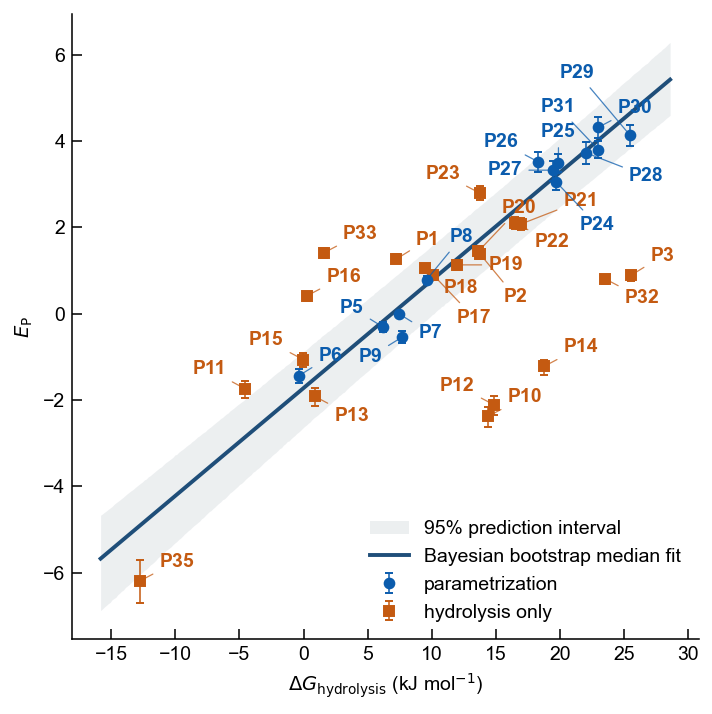

Saved figure to r2scan3c_Ep_vs_DeltaGhydrolysis_bayesian_bootstrap.png


In [6]:
fig, ax = plt.subplots(figsize=(5.2, 5.2))

ax.fill_between(
    x_grid,
    pred_lo,
    pred_hi,
    color="#9aa7b1",
    alpha=0.18,
    linewidth=0,
    label="95% prediction interval",
)
ax.plot(
    x_grid,
    line_med,
    color="#1f4e79",
    linewidth=2.0,
    label="Bayesian bootstrap median fit",
)

label_points = []
for subset, color, marker, label, zorder in [
    (fit_df, "#0b5cad", "o", "parametrization", 4),
    (test_df, "#c45a11", "s", "hydrolysis only", 3),
]:
    yerr = np.vstack([subset["EP_err_low"], subset["EP_err_high"]])
    ax.errorbar(
        subset["DeltaG_hydrolysis"],
        subset["EP"],
        yerr=yerr,
        fmt=marker,
        ms=5.0,
        color=color,
        ecolor=color,
        mec=color,
        mfc=color,
        lw=0.8,
        elinewidth=0.8,
        capsize=2,
        label=label,
        zorder=zorder,
    )
    for _, row in subset.iterrows():
        label_points.append({
            "label": row["Structure"],
            "x": float(row["DeltaG_hydrolysis"]),
            "y": float(row["EP"]),
            "color": color,
            "zorder": zorder,
        })

place_labels(ax, label_points)

ax.set_xlabel(r"$\Delta G_\mathrm{hydrolysis}$ (kJ mol$^{-1}$)")
ax.set_ylabel(r"$E_\mathrm{P}$")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.tick_params(axis="both", which="both", direction="in", top=False, right=False, length=5)
ax.xaxis.set_major_locator(MultipleLocator(5.0))
ax.yaxis.set_major_locator(MultipleLocator(2.0))
ax.grid(False)

handles, labels = ax.get_legend_handles_labels()
order = [0, 1, 2, 3]
ax.legend([handles[i] for i in order], [labels[i] for i in order], frameon=False, loc="lower right")

fig.tight_layout()
png_path = OUTPUT_DIR / "r2scan3c_Ep_vs_DeltaGhydrolysis_bayesian_bootstrap.png"
fig.savefig(png_path, bbox_inches="tight")
plt.show()

print(f"Saved figure to {png_path}")